## 0. Configuration

In [1]:
!pip -q install scikit-learn pandas matplotlib

In [2]:
import time, json, random, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset
import torchvision
from torchvision import datasets, transforms
from sklearn.metrics import f1_score, accuracy_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)
if device.type == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))
else:
    print("pas de GPU")

# ---------------- Paramètres globaux  ----------------
BATCH_SIZE   = 128
EPOCHS_CNN   = 5
EPOCHS_VIT   = 10
EPOCHS_FT    = 2      # fine-tuning VGG16 / AlexNet
EPOCHS_FRCNN = 3
N_TRAIN_FRCNN = 10000 # sous-ensemble pour Faster R-CNN (lent)
N_TEST_FRCNN  = 2000
N_TRAIN_FT    = 20000 # sous-ensemble pour VGG16/AlexNet (images 64x64x3)
N_TEST_FT     = 5000
RESULTS = {}          # stocke les métriques de chaque modèle

Device : cuda
GPU    : Tesla T4


### Données : MNIST


100%|██████████| 9.91M/9.91M [00:00<00:00, 19.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 471kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.38MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.40MB/s]


60000 10000 torch.Size([1, 28, 28])


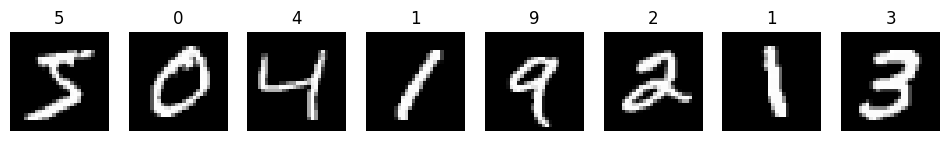

In [3]:
ROOT = "./data"
mnist_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_set = datasets.MNIST(ROOT, train=True,  download=True, transform=mnist_tf)
test_set  = datasets.MNIST(ROOT, train=False, download=True, transform=mnist_tf)
print(len(train_set), len(test_set), train_set[0][0].shape)

fig, ax = plt.subplots(1, 8, figsize=(12, 2))
for i, a in enumerate(ax):
    a.imshow(train_set[i][0][0], cmap="gray"); a.set_title(train_set[i][1]); a.axis("off")
plt.show()

### Fonctions utilitaires (entraînement / évaluation / métriques)

In [4]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, preds, labels = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        total_loss += criterion(out, y).item() * x.size(0)
        preds.append(out.argmax(1).cpu()); labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return {
        "loss": total_loss / len(labels),
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro"),
    }

def fit_classifier(model, train_loader, test_loader, epochs, optimizer, scheduler=None, name="model"):
    """Entraîne un classifieur, trace l'historique et retourne les métriques finales."""
    criterion = nn.CrossEntropyLoss()
    model.to(device)
    hist = {"train_loss": [], "test_loss": [], "test_acc": [], "test_f1": []}
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); run = 0.0; n = 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward(); optimizer.step()
            run += loss.item() * x.size(0); n += x.size(0)
        if scheduler: scheduler.step()
        m = evaluate(model, test_loader, criterion)
        hist["train_loss"].append(run / n); hist["test_loss"].append(m["loss"])
        hist["test_acc"].append(m["accuracy"]); hist["test_f1"].append(m["f1_macro"])
        print(f"[{name}] epoch {ep:02d}/{epochs} | train loss {run/n:.4f} | test loss {m['loss']:.4f} "
              f"| acc {m['accuracy']:.4f} | F1 {m['f1_macro']:.4f}")
    if device.type == "cuda": torch.cuda.synchronize()
    train_time = time.time() - t0
    final = evaluate(model, test_loader, criterion)
    RESULTS[name] = {**final, "train_time_s": train_time, "params": count_params(model), "history": hist}
    print(f"-> {name} : acc={final['accuracy']:.4f} F1={final['f1_macro']:.4f} "
          f"loss={final['loss']:.4f} temps={train_time:.1f}s")
    return model

def plot_history(name):
    h = RESULTS[name]["history"]; ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(ep, h["train_loss"], label="train"); ax[0].plot(ep, h["test_loss"], label="test")
    ax[0].set_title(f"{name} — Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, h["test_acc"], label="accuracy"); ax[1].plot(ep, h["test_f1"], label="F1 macro")
    ax[1].set_title(f"{name} — Test metrics"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_set,  batch_size=512,        shuffle=False, num_workers=2, pin_memory=True)

---
# Partie 1 : Classifieur CNN
## 1.1 Architecture CNN (PyTorch, GPU)

**Architecture** (entrée 1×28×28) :

| Couche | Détails | Sortie |
|---|---|---|
| Conv1 | 32 filtres, noyau 3×3, stride 1, padding 1 + BatchNorm + ReLU | 32×28×28 |
| MaxPool1 | 2×2, stride 2 | 32×14×14 |
| Conv2 | 64 filtres, noyau 3×3, stride 1, padding 1 + BatchNorm + ReLU | 64×14×14 |
| MaxPool2 | 2×2, stride 2 | 64×7×7 |
| Flatten + Dropout(0.5) | régularisation | 3136 |
| FC1 | 3136 → 128 + ReLU | 128 |
| FC2 | 128 → 10 (logits) | 10 |

**Hyperparamètres** : optimiseur **Adam** (lr = 1e-3), **weight decay** L2 = 1e-4, **Dropout** 0.5, **BatchNorm**,
scheduler `StepLR` (γ = 0.5 toutes les 2 époques), perte `CrossEntropyLoss`, batch = 128.

In [5]:
class CNN(nn.Module):
    def __init__(self, num_classes=10, p_drop=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2, 2),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(p_drop),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

cnn = CNN()
print(cnn); print("Paramètres entraînables :", count_params(cnn))

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.5, inplace=False)
    (2): Linear(in_features=3136, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Paramètres entraînables : 421834


[CNN] epoch 01/5 | train loss 0.1586 | test loss 0.0638 | acc 0.9786 | F1 0.9785
[CNN] epoch 02/5 | train loss 0.0670 | test loss 0.0527 | acc 0.9832 | F1 0.9831
[CNN] epoch 03/5 | train loss 0.0442 | test loss 0.0276 | acc 0.9916 | F1 0.9915
[CNN] epoch 04/5 | train loss 0.0369 | test loss 0.0342 | acc 0.9884 | F1 0.9884
[CNN] epoch 05/5 | train loss 0.0289 | test loss 0.0225 | acc 0.9929 | F1 0.9929
-> CNN : acc=0.9929 F1=0.9929 loss=0.0225 temps=80.2s


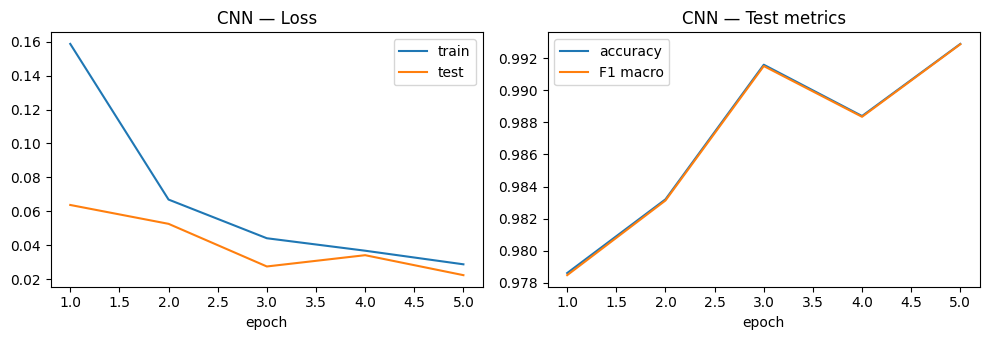

In [6]:
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=2, gamma=0.5)
cnn = fit_classifier(cnn, train_loader, test_loader, EPOCHS_CNN, opt, sched, name="CNN")
plot_history("CNN")

## 1.2 Faster R-CNN



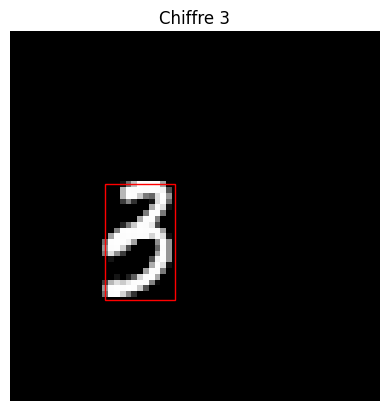

In [7]:
class MNISTDetection(Dataset):
    """MNIST placé sur un canevas 64x64 avec boîte englobante + label (digit+1)."""
    def __init__(self, base, n, canvas=64, seed=0):
        rng = np.random.RandomState(seed)
        idx = rng.permutation(len(base))[:n]
        self.base, self.idx, self.canvas = base, idx, canvas
        self.offsets = rng.randint(0, canvas - 28 + 1, size=(n, 2))
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        img, label = self.base.data[self.idx[i]], int(self.base.targets[self.idx[i]])
        oy, ox = self.offsets[i]
        canvas = torch.zeros(self.canvas, self.canvas)
        canvas[oy:oy+28, ox:ox+28] = img.float() / 255.0
        ys, xs = torch.where(canvas > 0.1)
        box = torch.tensor([[xs.min().item(), ys.min().item(), xs.max().item() + 1, ys.max().item() + 1]], dtype=torch.float32)
        image = canvas.unsqueeze(0).repeat(3, 1, 1)           # 3 canaux
        return image, {"boxes": box, "labels": torch.tensor([label + 1])}

def collate(batch): return tuple(zip(*batch))

det_train = MNISTDetection(datasets.MNIST(ROOT, train=True,  download=True), N_TRAIN_FRCNN, seed=1)
det_test  = MNISTDetection(datasets.MNIST(ROOT, train=False, download=True), N_TEST_FRCNN,  seed=2)
det_train_loader = DataLoader(det_train, batch_size=32, shuffle=True,  collate_fn=collate, num_workers=2)
det_test_loader  = DataLoader(det_test,  batch_size=64, shuffle=False, collate_fn=collate, num_workers=2)

# Aperçu
img, tgt = det_train[0]
b = tgt["boxes"][0]
plt.imshow(img[0], cmap="gray")
plt.gca().add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, edgecolor="red"))
plt.title(f"Chiffre {tgt['labels'].item()-1}"); plt.axis("off"); plt.show()

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 98.1MB/s]


Paramètres entraînables : 18917458
[Faster R-CNN] epoch 1/3 | train loss nan | test loss nan | acc 0.0000 | F1 0.0000 | IoU 0.000 | sans détection 1.000
[Faster R-CNN] epoch 2/3 | train loss nan | test loss nan | acc 0.0000 | F1 0.0000 | IoU 0.000 | sans détection 1.000
[Faster R-CNN] epoch 3/3 | train loss nan | test loss nan | acc 0.0000 | F1 0.0000 | IoU 0.000 | sans détection 1.000
-> Faster R-CNN : acc=0.0000 F1=0.0000 IoU=0.000 temps=305.4s


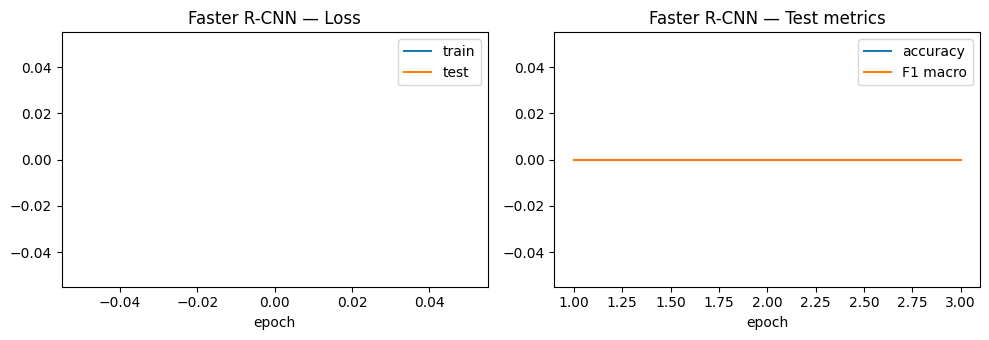

In [8]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn

PRETRAINED_BACKBONE = True   # backbone MobileNetV3 pré-entraîné ImageNet (les têtes RPN/RoI restent à entraîner)

def build_frcnn():
    kw = dict(weights=None, num_classes=11,                    # 10 chiffres + fond
              min_size=64, max_size=64,                        # pas de redimensionnement
              box_score_thresh=0.0, box_detections_per_img=5)  # seuil 0 : on garde toujours la meilleure détection
    try:
        return fasterrcnn_mobilenet_v3_large_320_fpn(weights_backbone="IMAGENET1K_V1" if PRETRAINED_BACKBONE else None, **kw)
    except Exception as e:
        print("Backbone pré-entraîné indisponible, entraînement from scratch :", e)
        return fasterrcnn_mobilenet_v3_large_320_fpn(weights_backbone=None, **kw)

@torch.no_grad()
def evaluate_frcnn(model, loader):
    model.eval()
    preds, labels, ious = [], [], []
    for imgs, tgts in loader:
        outs = model([i.to(device) for i in imgs])
        for o, t in zip(outs, tgts):
            labels.append(t["labels"].item() - 1)
            if len(o["scores"]) == 0:
                preds.append(-1); ious.append(0.0)
            else:
                k = o["scores"].argmax()
                preds.append(o["labels"][k].item() - 1)
                ious.append(torchvision.ops.box_iou(o["boxes"][k:k+1].cpu(), t["boxes"])[0, 0].item())
    preds, labels = np.array(preds), np.array(labels)
    return {"accuracy": accuracy_score(labels, preds),
            "f1_macro": f1_score(labels, preds, average="macro", labels=list(range(10))),
            "mean_iou": float(np.mean(ious)),
            "no_detection_rate": float(np.mean(preds == -1))}

@torch.no_grad()
def frcnn_val_loss(model, loader):
    model.train()   # torchvision renvoie les pertes uniquement en mode train (pas de dropout/BN-update ici : no_grad)
    tot, n = 0.0, 0
    for imgs, tgts in loader:
        imgs = [i.to(device) for i in imgs]; tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
        tot += sum(model(imgs, tgts).values()).item() * len(imgs); n += len(imgs)
    return tot / n

frcnn = build_frcnn().to(device)
print("Paramètres entraînables :", count_params(frcnn))
params = [p for p in frcnn.parameters() if p.requires_grad]
opt = torch.optim.SGD(params, lr=0.01, momentum=0.9, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=2, gamma=0.1)

hist = {"train_loss": [], "test_loss": [], "test_acc": [], "test_f1": []}
if device.type == "cuda": torch.cuda.synchronize()
t0 = time.time()
for ep in range(1, EPOCHS_FRCNN + 1):
    frcnn.train(); run, n = 0.0, 0
    for imgs, tgts in det_train_loader:
        imgs = [i.to(device) for i in imgs]; tgts = [{k: v.to(device) for k, v in t.items()} for t in tgts]
        loss = sum(frcnn(imgs, tgts).values())
        opt.zero_grad(); loss.backward(); opt.step()
        run += loss.item() * len(imgs); n += len(imgs)
    sched.step()
    m = evaluate_frcnn(frcnn, det_test_loader); vl = frcnn_val_loss(frcnn, det_test_loader)
    hist["train_loss"].append(run / n); hist["test_loss"].append(vl)
    hist["test_acc"].append(m["accuracy"]); hist["test_f1"].append(m["f1_macro"])
    print(f"[Faster R-CNN] epoch {ep}/{EPOCHS_FRCNN} | train loss {run/n:.4f} | test loss {vl:.4f} "
          f"| acc {m['accuracy']:.4f} | F1 {m['f1_macro']:.4f} | IoU {m['mean_iou']:.3f} | sans détection {m['no_detection_rate']:.3f}")
if device.type == "cuda": torch.cuda.synchronize()
t_frcnn = time.time() - t0
final = evaluate_frcnn(frcnn, det_test_loader)
RESULTS["Faster R-CNN"] = {"loss": hist["test_loss"][-1], "accuracy": final["accuracy"], "f1_macro": final["f1_macro"],
                           "train_time_s": t_frcnn, "params": count_params(frcnn), "history": hist,
                           "mean_iou": final["mean_iou"]}
print(f"-> Faster R-CNN : acc={final['accuracy']:.4f} F1={final['f1_macro']:.4f} IoU={final['mean_iou']:.3f} temps={t_frcnn:.1f}s")
plot_history("Faster R-CNN")

## 1.3 Comparaison CNN vs Faster R-CNN

,Accuracy,F1 (macro),Loss,Temps d'entraînement (s),Paramètres
Modèle,,,,,
CNN,0.9929,0.9929,0.0225,80.2,421834
Faster R-CNN,0.0000,0.0000,NaN,305.4,18917458


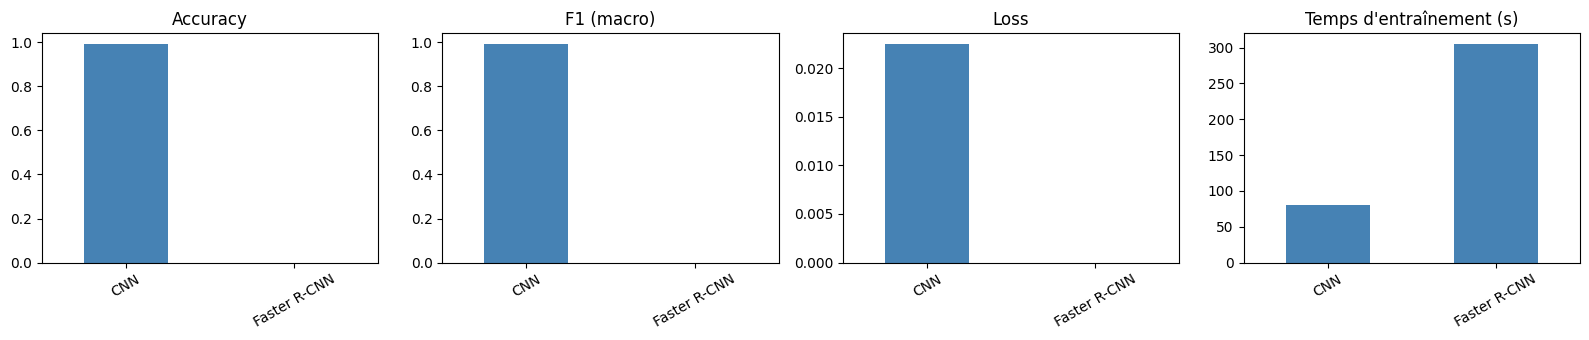

In [9]:
def results_table(names=None):
    names = names or list(RESULTS)
    rows = []
    for n in names:
        r = RESULTS[n]
        rows.append({"Modèle": n, "Accuracy": round(r["accuracy"], 4), "F1 (macro)": round(r["f1_macro"], 4),
                     "Loss": round(r["loss"], 4), "Temps d'entraînement (s)": round(r["train_time_s"], 1),
                     "Paramètres": r["params"]})
    return pd.DataFrame(rows).set_index("Modèle")

def plot_comparison(names=None):
    df = results_table(names)
    fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
    for a, col in zip(ax, ["Accuracy", "F1 (macro)", "Loss", "Temps d'entraînement (s)"]):
        df[col].plot.bar(ax=a, color="steelblue"); a.set_title(col); a.set_xlabel(""); a.tick_params(axis="x", rotation=30)
    plt.tight_layout(); plt.show()

display(results_table(["CNN", "Faster R-CNN"]))
plot_comparison(["CNN", "Faster R-CNN"])

## 1.4 Fine-tuning de VGG16 et AlexNet (pré-entraînés ImageNet)

Les modèles ImageNet attendent des images **RGB**. On convertit donc MNIST : redimensionnement en **64×64**, duplication sur 3 canaux,
normalisation ImageNet. Stratégie de fine-tuning :

1. on charge les poids ImageNet (`weights="IMAGENET1K_V1"`),
2. on **gèle** la partie convolutive (`features`) → extraction de caractéristiques,
3. on **remplace la dernière couche** `Linear(4096, 1000)` par `Linear(4096, 10)`,
4. on entraîne le classifieur (Adam, lr = 1e-4).


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 182MB/s]


AlexNet : paramètres entraînables = 54,575,114
[AlexNet (fine-tuned)] epoch 01/2 | train loss 0.4865 | test loss 0.2451 | acc 0.9174 | F1 0.9167
[AlexNet (fine-tuned)] epoch 02/2 | train loss 0.2760 | test loss 0.2048 | acc 0.9344 | F1 0.9341
-> AlexNet (fine-tuned) : acc=0.9344 F1=0.9341 loss=0.2048 temps=25.4s


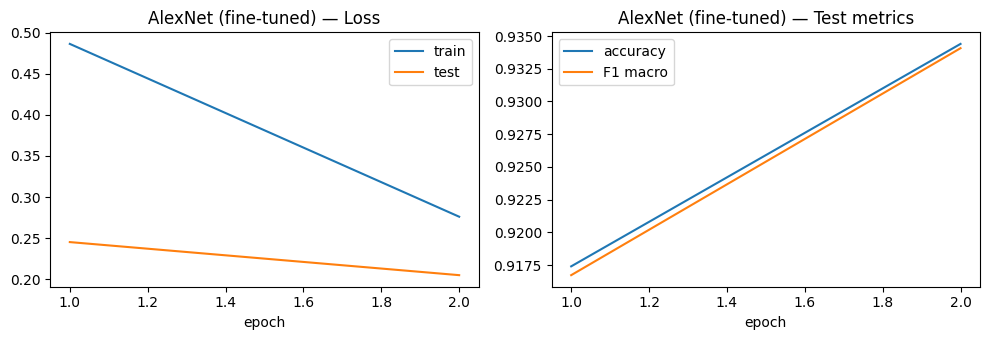

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 69.3MB/s]


VGG16 : paramètres entraînables = 119,586,826
[VGG16 (fine-tuned)] epoch 01/2 | train loss 0.3696 | test loss 0.1618 | acc 0.9468 | F1 0.9471
[VGG16 (fine-tuned)] epoch 02/2 | train loss 0.1531 | test loss 0.1122 | acc 0.9644 | F1 0.9644
-> VGG16 (fine-tuned) : acc=0.9644 F1=0.9644 loss=0.1122 temps=55.2s


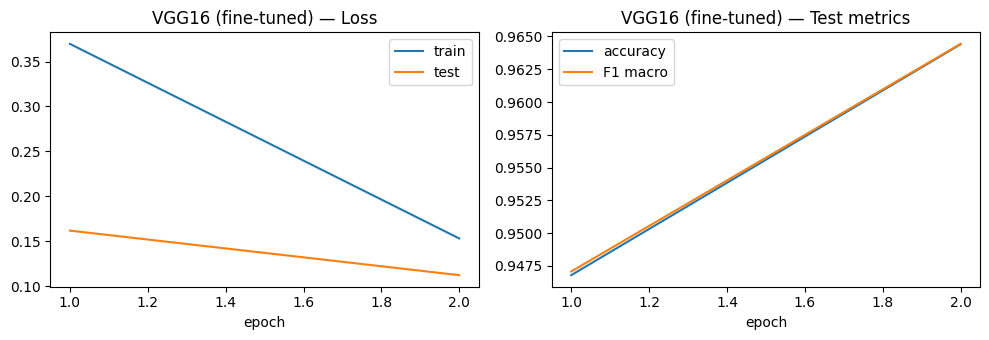

In [10]:
from torchvision.models import vgg16, alexnet

UNFREEZE_LAST_BLOCK = False
ft_tf = transforms.Compose([
    transforms.Resize(64), transforms.Grayscale(3), transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
ft_train_full = datasets.MNIST(ROOT, train=True,  download=True, transform=ft_tf)
ft_test_full  = datasets.MNIST(ROOT, train=False, download=True, transform=ft_tf)
g = torch.Generator().manual_seed(SEED)
ft_train = Subset(ft_train_full, torch.randperm(len(ft_train_full), generator=g)[:N_TRAIN_FT].tolist())
ft_test  = Subset(ft_test_full,  torch.randperm(len(ft_test_full),  generator=g)[:N_TEST_FT].tolist())
ft_train_loader = DataLoader(ft_train, batch_size=64, shuffle=True,  num_workers=2, pin_memory=True)
ft_test_loader  = DataLoader(ft_test,  batch_size=256, shuffle=False, num_workers=2, pin_memory=True)

def make_finetune_model(arch):
    if arch == "VGG16":
        m = vgg16(weights="IMAGENET1K_V1"); last_block_start = 24    # dernier bloc conv de VGG16
    else:
        m = alexnet(weights="IMAGENET1K_V1"); last_block_start = 10  # dernière conv d'AlexNet
    for p in m.features.parameters(): p.requires_grad = False
    if UNFREEZE_LAST_BLOCK:
        for p in m.features[last_block_start:].parameters(): p.requires_grad = True
    m.classifier[-1] = nn.Linear(4096, 10)    # nouvelle tête (10 classes), entraînable
    return m

for arch in ["AlexNet", "VGG16"]:
    model = make_finetune_model(arch)
    print(f"{arch} : paramètres entraînables = {count_params(model):,}")
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-4, weight_decay=1e-4)
    fit_classifier(model, ft_train_loader, ft_test_loader, EPOCHS_FT, opt, name=f"{arch} (fine-tuned)")
    plot_history(f"{arch} (fine-tuned)")
    del model, opt
    if device.type == "cuda": torch.cuda.empty_cache()

,Accuracy,F1 (macro),Loss,Temps d'entraînement (s),Paramètres
Modèle,,,,,
CNN,0.9929,0.9929,0.0225,80.2,421834
Faster R-CNN,0.0000,0.0000,NaN,305.4,18917458
AlexNet (fine-tuned),0.9344,0.9341,0.2048,25.4,54575114
VGG16 (fine-tuned),0.9644,0.9644,0.1122,55.2,119586826


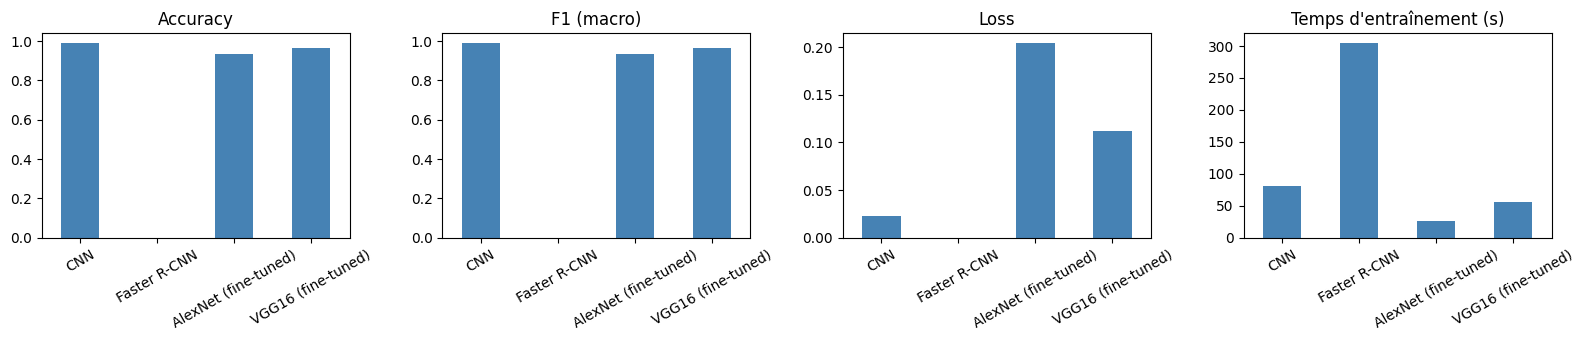

In [11]:
display(results_table(["CNN", "Faster R-CNN", "AlexNet (fine-tuned)", "VGG16 (fine-tuned)"]))
plot_comparison(["CNN", "Faster R-CNN", "AlexNet (fine-tuned)", "VGG16 (fine-tuned)"])

---
# Partie 2 : Vision Transformer (ViT) from scratch

Implémentation  :

1. **Patchification** : l'image 28×28 est découpée en patchs (4×4 → 49 patchs de 16 pixels).
2. **Embedding linéaire** de chaque patch (16 → `hidden_d`).
3. Ajout d'un **token de classification** `[CLS]`.
4. Ajout des **encodages positionnels** sinusoïdaux (fixes), comme dans le tutoriel.
5. **Blocs Transformer** : `LayerNorm → Multi-Head Self-Attention (écrite à la main) → résidu → LayerNorm → MLP → résidu`.
6. **Tête de classification** : on prend la sortie du token `[CLS]` → `Linear → 10`.

Hyperparamètres : `hidden_d = 64`, 4 têtes, 4 blocs, MLP ratio 4, optimiseur **AdamW** (lr = 1e-3, weight decay 1e-2), scheduler cosinus, 10 époques.

In [12]:
def patchify(images, patch_size):
    # (B, C, H, W) -> (B, n_patches, C*p*p)
    B, C, H, W = images.shape
    p = patch_size
    patches = images.unfold(2, p, p).unfold(3, p, p)                  # B,C,H/p,W/p,p,p
    return patches.permute(0, 2, 3, 1, 4, 5).reshape(B, (H // p) * (W // p), C * p * p)

def positional_embeddings(n_tokens, d):
    pe = torch.zeros(n_tokens, d)
    pos = torch.arange(n_tokens).unsqueeze(1).float()
    div = 10000 ** (torch.arange(0, d, 2).float() / d)
    pe[:, 0::2] = torch.sin(pos / div); pe[:, 1::2] = torch.cos(pos / div)
    return pe

class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        assert d % n_heads == 0
        self.h, self.dh = n_heads, d // n_heads
        self.q, self.k, self.v = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d)
        self.out = nn.Linear(d, d)
    def forward(self, x):
        B, N, D = x.shape
        q = self.q(x).view(B, N, self.h, self.dh).transpose(1, 2)     # B,h,N,dh
        k = self.k(x).view(B, N, self.h, self.dh).transpose(1, 2)
        v = self.v(x).view(B, N, self.h, self.dh).transpose(1, 2)
        attn = torch.softmax(q @ k.transpose(-2, -1) / self.dh ** 0.5, dim=-1)   # B,h,N,N
        out = (attn @ v).transpose(1, 2).reshape(B, N, D)
        return self.out(out)

class ViTBlock(nn.Module):
    def __init__(self, d, n_heads, mlp_ratio=4, p_drop=0.1):
        super().__init__()
        self.n1, self.attn = nn.LayerNorm(d), MultiHeadSelfAttention(d, n_heads)
        self.n2 = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, mlp_ratio * d), nn.GELU(), nn.Dropout(p_drop), nn.Linear(mlp_ratio * d, d))
        self.drop = nn.Dropout(p_drop)
    def forward(self, x):
        x = x + self.drop(self.attn(self.n1(x)))
        return x + self.drop(self.mlp(self.n2(x)))

class ViT(nn.Module):
    def __init__(self, in_shape=(1, 28, 28), patch_size=4, d=64, n_heads=4, n_blocks=4, n_classes=10):
        super().__init__()
        C, H, W = in_shape
        assert H % patch_size == 0 and W % patch_size == 0
        self.p = patch_size
        self.n_patches = (H // patch_size) * (W // patch_size)
        self.embed = nn.Linear(C * patch_size ** 2, d)
        self.cls = nn.Parameter(torch.randn(1, 1, d) * 0.02)
        self.register_buffer("pos", positional_embeddings(self.n_patches + 1, d))
        self.blocks = nn.ModuleList([ViTBlock(d, n_heads) for _ in range(n_blocks)])
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, n_classes)
    def forward(self, x):
        tokens = self.embed(patchify(x, self.p))
        tokens = torch.cat([self.cls.expand(x.size(0), -1, -1), tokens], dim=1) + self.pos
        for blk in self.blocks: tokens = blk(tokens)
        return self.head(self.norm(tokens)[:, 0])        # sortie du token [CLS]

vit = ViT()
print("Paramètres entraînables :", count_params(vit))
# vérification des formes
print(vit(torch.randn(2, 1, 28, 28)).shape)

Paramètres entraînables : 201866
torch.Size([2, 10])


[ViT (scratch)] epoch 01/10 | train loss 0.7047 | test loss 0.1749 | acc 0.9467 | F1 0.9460
[ViT (scratch)] epoch 02/10 | train loss 0.1825 | test loss 0.1115 | acc 0.9642 | F1 0.9637
[ViT (scratch)] epoch 03/10 | train loss 0.1279 | test loss 0.0898 | acc 0.9710 | F1 0.9706
[ViT (scratch)] epoch 04/10 | train loss 0.1007 | test loss 0.0846 | acc 0.9750 | F1 0.9747
[ViT (scratch)] epoch 05/10 | train loss 0.0792 | test loss 0.0716 | acc 0.9779 | F1 0.9776
[ViT (scratch)] epoch 06/10 | train loss 0.0614 | test loss 0.0641 | acc 0.9801 | F1 0.9799
[ViT (scratch)] epoch 07/10 | train loss 0.0507 | test loss 0.0609 | acc 0.9811 | F1 0.9810
[ViT (scratch)] epoch 08/10 | train loss 0.0392 | test loss 0.0576 | acc 0.9812 | F1 0.9811
[ViT (scratch)] epoch 09/10 | train loss 0.0307 | test loss 0.0512 | acc 0.9846 | F1 0.9845
[ViT (scratch)] epoch 10/10 | train loss 0.0263 | test loss 0.0495 | acc 0.9849 | F1 0.9848
-> ViT (scratch) : acc=0.9849 F1=0.9848 loss=0.0495 temps=183.0s


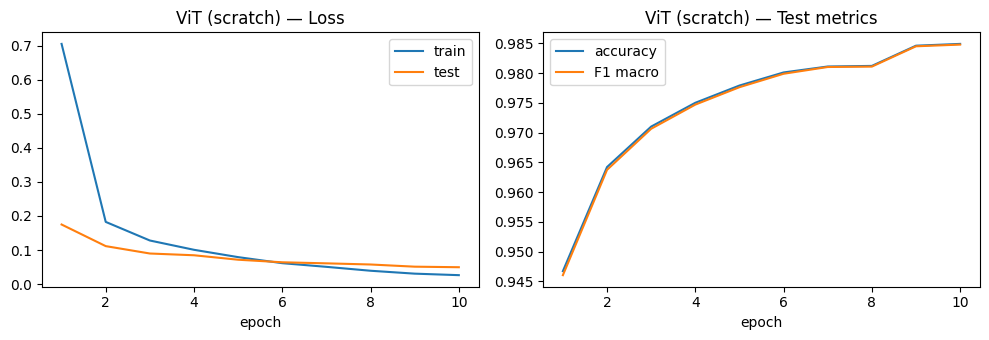

In [13]:
opt = torch.optim.AdamW(vit.parameters(), lr=1e-3, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS_VIT)
vit = fit_classifier(vit, train_loader, test_loader, EPOCHS_VIT, opt, sched, name="ViT (scratch)")
plot_history("ViT (scratch)")

### Visualisation de l'attention du token [CLS] (interprétation)

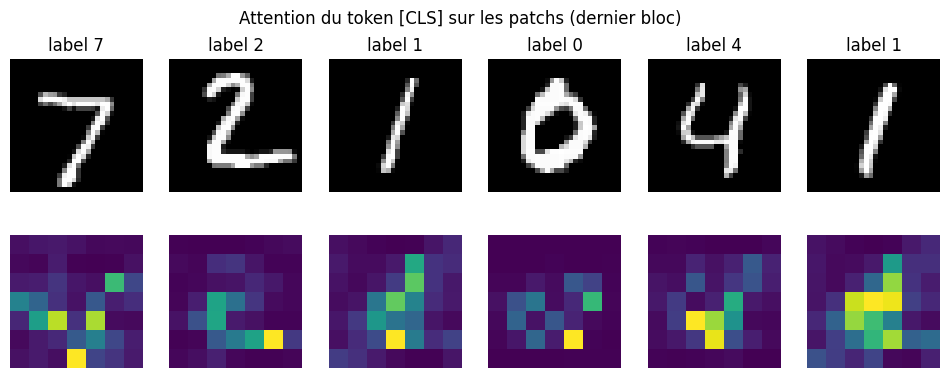

In [14]:
@torch.no_grad()
def cls_attention_map(model, img):
    model.eval()
    x = img.unsqueeze(0).to(device)
    tokens = model.embed(patchify(x, model.p))
    tokens = torch.cat([model.cls.expand(1, -1, -1), tokens], dim=1) + model.pos
    for blk in model.blocks[:-1]: tokens = blk(tokens)
    last = model.blocks[-1]; a = last.attn; z = last.n1(tokens)
    B, N, D = z.shape
    q = a.q(z).view(B, N, a.h, a.dh).transpose(1, 2); k = a.k(z).view(B, N, a.h, a.dh).transpose(1, 2)
    attn = torch.softmax(q @ k.transpose(-2, -1) / a.dh ** 0.5, dim=-1)[0].mean(0)   # moyenne sur les têtes
    g = int(model.n_patches ** 0.5)
    return attn[0, 1:].reshape(g, g).cpu()

fig, ax = plt.subplots(2, 6, figsize=(12, 4.2))
for i in range(6):
    img, y = test_set[i]
    ax[0, i].imshow(img[0], cmap="gray"); ax[0, i].set_title(f"label {y}"); ax[0, i].axis("off")
    ax[1, i].imshow(cls_attention_map(vit, img), cmap="viridis"); ax[1, i].axis("off")
ax[0, 0].set_ylabel("image"); plt.suptitle("Attention du token [CLS] sur les patchs (dernier bloc)"); plt.show()

## Comparaison finale : tous les modèles

,Accuracy,F1 (macro),Loss,Temps d'entraînement (s),Paramètres
Modèle,,,,,
CNN,0.9929,0.9929,0.0225,80.2,421834
Faster R-CNN,0.0000,0.0000,NaN,305.4,18917458
AlexNet (fine-tuned),0.9344,0.9341,0.2048,25.4,54575114
VGG16 (fine-tuned),0.9644,0.9644,0.1122,55.2,119586826
ViT (scratch),0.9849,0.9848,0.0495,183.0,201866


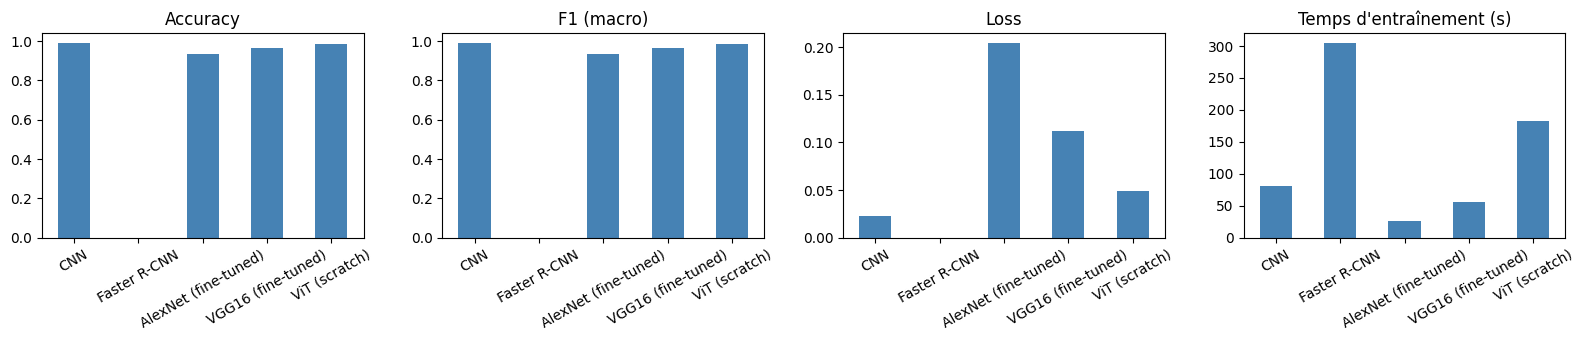

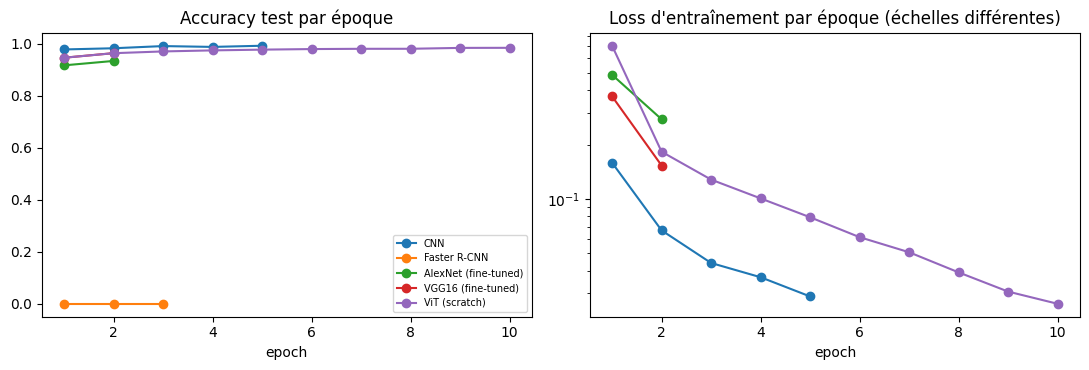

Résultats sauvegardés : resultats_lab2.csv / resultats_lab2.json


In [15]:
final_df = results_table()
display(final_df)
plot_comparison()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for n in RESULTS:
    h = RESULTS[n]["history"]; e = range(1, len(h["test_acc"]) + 1)
    ax[0].plot(e, h["test_acc"], marker="o", label=n); ax[1].plot(e, h["train_loss"], marker="o", label=n)
ax[0].set_title("Accuracy test par époque"); ax[0].set_xlabel("epoch"); ax[0].legend(fontsize=7)
ax[1].set_title("Loss d'entraînement par époque (échelles différentes)"); ax[1].set_xlabel("epoch"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

final_df.to_csv("resultats_lab2.csv")
with open("resultats_lab2.json", "w") as f:
    json.dump({k: {kk: vv for kk, vv in v.items()} for k, v in RESULTS.items()}, f, indent=2)
print("Résultats sauvegardés : resultats_lab2.csv / resultats_lab2.json")